# Conect to google drive

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


# Libraries

## External

In [ ]:
!pip install -q wfdb einops remotezip
print("done!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.0/160.0 kB 14.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 6.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
done!


In [ ]:
import os
import wfdb
from matplotlib import pyplot as plt
from tqdm import tqdm
import tensorflow as tf
import seaborn as sns
import keras

%matplotlib inline
sns.set_theme()

## Internal

In [ ]:
import sys
sys.path.append('/content/gdrive/MyDrive/Doutorado/emg_estimator')

In [ ]:
from utils.utils import *
from dataloader.dataloader import *
from models.estimator import estimator
from models.data_augmentation import *

## Create paths

In [ ]:
sys.path.append('/content/gdrive')

In [ ]:
path = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject01_session1"
dir_list = os.listdir(path)

path2 = "gdrive/MyDrive/Colab Notebooks/1dof_dataset/subject01_session2"
dir_list2 = os.listdir(path2)

## Create the datasets

### Training dataset

In [ ]:
emg_files_train_finger1 = [
    "1dof_preprocess_finger1_sample1.hea",
    "1dof_preprocess_finger1_sample2.hea",
]
emg_files_train_finger2 = [
    "1dof_preprocess_finger2_sample1.hea",
    "1dof_preprocess_finger2_sample2.hea",
]
emg_files_train_finger3 = [
    "1dof_preprocess_finger3_sample1.hea",
    "1dof_preprocess_finger3_sample2.hea",
]
emg_files_train_finger4 = [
    "1dof_preprocess_finger4_sample1.hea",
    "1dof_preprocess_finger4_sample2.hea",
]
emg_files_train_finger5 = [
    "1dof_preprocess_finger5_sample1.hea",
    "1dof_preprocess_finger5_sample2.hea",
]

force_files_train_finger1 = [
    "1dof_force_finger1_sample1.hea",
    "1dof_force_finger1_sample2.hea",
]
force_files_train_finger2 = [
    "1dof_force_finger2_sample1.hea",
    "1dof_force_finger2_sample2.hea",
]
force_files_train_finger3 = [
    "1dof_force_finger3_sample1.hea",
    "1dof_force_finger3_sample2.hea",
]
force_files_train_finger4 = [
    "1dof_force_finger4_sample1.hea",
    "1dof_force_finger4_sample2.hea",
]
force_files_train_finger5 = [
    "1dof_force_finger5_sample1.hea",
    "1dof_force_finger5_sample2.hea",
]

In [ ]:
train_dataset_f1 = create_synced_datasets(
    path, emg_files_train_finger1, force_files_train_finger1
) # train_weights
train_dataset_f2 = create_synced_datasets(
    path, emg_files_train_finger2, force_files_train_finger2
)
train_dataset_f3 = create_synced_datasets(
    path, emg_files_train_finger3, force_files_train_finger3
)
train_dataset_f4 = create_synced_datasets(
    path, emg_files_train_finger4, force_files_train_finger4
)
train_dataset_f5 = create_synced_datasets(
    path, emg_files_train_finger5, force_files_train_finger5
)

### Validation dataset

In [ ]:
emg_files_val_finger1 = [
    "1dof_preprocess_finger1_sample3.hea",
]
emg_files_val_finger2 = [
    "1dof_preprocess_finger2_sample3.hea",
]
emg_files_val_finger3 = [
    "1dof_preprocess_finger3_sample3.hea",
]
emg_files_val_finger4 = [
    "1dof_preprocess_finger4_sample3.hea",
]
emg_files_val_finger5 = [
    "1dof_preprocess_finger5_sample3.hea",
]

force_files_val_finger1 = [
    "1dof_force_finger1_sample3.hea",
]
force_files_val_finger2 = [
    "1dof_force_finger2_sample3.hea",
]
force_files_val_finger3 = [
    "1dof_force_finger3_sample3.hea",
]
force_files_val_finger4 = [
    "1dof_force_finger4_sample3.hea",
]
force_files_val_finger5 = [
    "1dof_force_finger5_sample3.hea",
]

In [ ]:
val_dataset_f1 = create_synced_datasets(
    path, emg_files_val_finger1, force_files_val_finger1
) # val_weights
val_dataset_f2 = create_synced_datasets(
    path, emg_files_val_finger2, force_files_val_finger2
)
val_dataset_f3 = create_synced_datasets(
    path, emg_files_val_finger3, force_files_val_finger3
)
val_dataset_f4 = create_synced_datasets(
    path, emg_files_val_finger4, force_files_val_finger4
)
val_dataset_f5 = create_synced_datasets(
    path, emg_files_val_finger5, force_files_val_finger5
)

In [ ]:
emg_files_test_finger1 = [
    # "1dof_preprocess_finger1_sample1.hea",
    # "1dof_preprocess_finger1_sample2.hea",
    "1dof_preprocess_finger1_sample3.hea",
]
emg_files_test_finger2 = [
    # "1dof_preprocess_finger2_sample1.hea",
    # "1dof_preprocess_finger2_sample2.hea",
    "1dof_preprocess_finger2_sample3.hea",
]
emg_files_test_finger3 = [
    # "1dof_preprocess_finger3_sample1.hea",
    # "1dof_preprocess_finger3_sample2.hea",
    "1dof_preprocess_finger3_sample3.hea",
]
emg_files_test_finger4 = [
    # "1dof_preprocess_finger4_sample1.hea",
    # "1dof_preprocess_finger4_sample2.hea",
    "1dof_preprocess_finger4_sample3.hea",
]
emg_files_test_finger5 = [
    # "1dof_preprocess_finger5_sample1.hea",
    # "1dof_preprocess_finger5_sample2.hea",
    "1dof_preprocess_finger5_sample3.hea",
]

force_files_test_finger1 = [
    # "1dof_force_finger1_sample1.hea",
    # "1dof_force_finger1_sample2.hea",
    "1dof_force_finger1_sample3.hea",
]
force_files_test_finger2 = [
    # "1dof_force_finger2_sample1.hea",
    # "1dof_force_finger2_sample2.hea",
    "1dof_force_finger2_sample3.hea",
]
force_files_test_finger3 = [
    # "1dof_force_finger3_sample1.hea",
    # "1dof_force_finger3_sample2.hea",
    "1dof_force_finger3_sample3.hea",
]
force_files_test_finger4 = [
    # "1dof_force_finger4_sample1.hea",
    # "1dof_force_finger4_sample2.hea",
    "1dof_force_finger4_sample3.hea",
]
force_files_test_finger5 = [
    "1dof_force_finger5_sample1.hea",
    # "1dof_force_finger5_sample2.hea",
    "1dof_force_finger5_sample3.hea",
]

In [ ]:
test_dataset_f1 = create_synced_datasets(
    path2, emg_files_test_finger1, force_files_test_finger1
) # , _
test_dataset_f2 = create_synced_datasets(
    path2, emg_files_test_finger2, force_files_test_finger2
)
test_dataset_f3 = create_synced_datasets(
    path2, emg_files_test_finger3, force_files_test_finger3
)
test_dataset_f4 = create_synced_datasets(
    path2, emg_files_test_finger4, force_files_test_finger4
)
test_dataset_f5 = create_synced_datasets(
    path2, emg_files_test_finger5, force_files_test_finger5
)

# Create the base model

In [ ]:
kernel_size=(18, 3, 3)
dilations=[1, 2, 4]
num_lstm_blocks = 1
input_shape = [100, 16, 16, 1] # train_dataset.element_spec[0].shape

estimator_f1 = estimator(
    num_blocks=2, num_layers=3, filters=16
    , kernel_size=kernel_size,
    dilations=dilations, input_shape_=input_shape,
    # num_lstm_blocks=num_lstm_blocks
)

estimator_f1.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 100, 16, 16  0           []                               
                                , 1)]                                                             
                                                                                                  
 dilated_conv2_plus1d (DilatedC  (None, 100, 16, 16,  4912       ['input_1[0][0]']                
 onv2Plus1D)                     16)                                                              
                                                                                                  
 dilated_conv2_plus1d_1 (Dilate  (None, 100, 16, 16,  7072       ['dilated_conv2_plus1d[0][0]']   
 dConv2Plus1D)                   16)                                                          

## Load models

In [ ]:
estimator_f1 = estimator_f1
estimator_f2 = estimator_f1
estimator_f3 = estimator_f1
estimator_f4 = estimator_f1
estimator_f5 = estimator_f1

In [ ]:
# Cria um objeto `tf.train.Checkpoint` com o modelo
checkpoint1 = tf.train.Checkpoint(model=estimator_f1)

# Restaura os valores salvos no modelo a partir dos arquivos de checkpoint
checkpoint1.restore(
    "gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_1/"
)

In [ ]:
checkpoint2 = tf.train.Checkpoint(model=estimator_f2)

# Restaura os valores salvos no modelo a partir dos arquivos de checkpoint
checkpoint2.restore(
    "gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_2/"
)

In [ ]:
checkpoint3 = tf.train.Checkpoint(model=estimator_f3)

# Restaura os valores salvos no modelo a partir dos arquivos de checkpoint
checkpoint3.restore(
    "gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_3/"
)

In [ ]:
checkpoint4 = tf.train.Checkpoint(model=estimator_f4)

# Restaura os valores salvos no modelo a partir dos arquivos de checkpoint
checkpoint4.restore(
    "gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_4/"
)

In [ ]:
checkpoint5 = tf.train.Checkpoint(model=estimator_f5)

# Restaura os valores salvos no modelo a partir dos arquivos de checkpoint
checkpoint5.restore(
    "gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/estimator_5/"
)

## Weighted mean of the models

In [ ]:
import numpy as np

In [ ]:
averaged_model = estimator_f1

model_list = [estimator_f1, estimator_f2, estimator_f3, estimator_f4, estimator_f5]

# Obtenha os pesos de cada modelo
weights_list = [model.get_weights() for model in model_list]

# Calcule a média dos pesos
averaged_weights = np.mean(weights_list, axis=0)

# Atribua os pesos médios ao modelo final
averaged_model.set_weights(averaged_weights)

/usr/local/lib/python3.10/dist-packages/numpy/core/_methods.py:163: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  arr = asanyarray(a)


## Create the dataloader for training and validation

In [ ]:
batch_size = 8

dataset_train_f1 = train_dataset_f1.shuffle(buffer_size=len(train_dataset_f1)).batch(batch_size)
dataset_val_f1 = val_dataset_f1.batch(batch_size)

## Callbacks

In [ ]:
callback = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath="gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/transfer_estimator_1/",
        monitor="val_loss",
        verbose=1,
        save_best_only=True,
        save_weights_only=True,
        mode="min",
    ),
    tf.keras.callbacks.TensorBoard(
      log_dir='gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_tensorboard/transfer_estimator_1/',
      histogram_freq=0,
      write_graph=True,
      write_images=False,
      write_steps_per_second=False,
      update_freq='epoch',
      profile_batch=0,
      embeddings_freq=0,
      embeddings_metadata=None,
    ),
    tf.keras.callbacks.EarlyStopping(
      patience=30,
      restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.75,
        patience=5,
        min_lr=1e-8,
    ),
]

## Transfer learning of the linear combinator

### Finger 1

In [ ]:
# Carregue o modelo pré-treinado
pretrained_model = averaged_model

# Congele as camadas
for layer in pretrained_model.layers:
    layer.trainable = False

# Adicione a nova camada de saída
output_layer = tf.keras.layers.Dense(1, activation='linear')(pretrained_model.layers[-2].output)

# Crie o novo modelo com a camada de saída modificada
estimator_f1 = tf.keras.Model(inputs=pretrained_model.inputs, outputs=output_layer)

model_f1 = tf.keras.Sequential([
  # data_augmentation,
  estimator_f1,
])

# Compile o modelo
model_f1.compile(optimizer='adam', loss='mse')

# Treine apenas a última camada
history = model_f1.fit(
    dataset_train_f1,
    validation_data=dataset_val_f1,
    epochs=100,
    callbacks=callback,
)

Epoch 1/100
599/599 [==============================] - ETA: 0s - loss: 0.0547
Epoch 1: val_loss improved from 0.04912 to 0.04539, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/transfer_estimator_1/
599/599 [==============================] - 45s 71ms/step - loss: 0.0547 - val_loss: 0.0454 - lr: 0.0010
Epoch 2/100
598/599 [============================>.] - ETA: 0s - loss: 0.0416
Epoch 2: val_loss improved from 0.04539 to 0.04365, saving model to gdrive/MyDrive/Doutorado/emg_estimator/logs/model_1DoF_checkpoint/transfer_estimator_1/
599/599 [==============================] - 41s 68ms/step - loss: 0.0417 - val_loss: 0.0437 - lr: 0.0010
Epoch 3/100
599/599 [==============================] - ETA: 0s - loss: 0.0411
Epoch 3: val_loss did not improve from 0.04365
599/599 [==============================] - 41s 68ms/step - loss: 0.0411 - val_loss: 0.0449 - lr: 0.0010
Epoch 4/100
598/599 [============================>.] - ETA: 0s - loss: 0.0409
Epoch 4: val_loss

In [ ]:
emg_signal_windows_test, force_signal_test = [], []
for emg, f in test_dataset_f1:
    emg_signal_windows_test.append(emg)
    force_signal_test.append(f)
emg_signal_windows_test = tf.constant(
    np.array(emg_signal_windows_test)
)
force_signal_test = tf.constant(
    np.array(force_signal_test)
)[:,0]

print(emg_signal_windows_test.shape)
print(force_signal_test.shape)

(2395, 100, 16, 16, 1)
(2395,)


In [ ]:
predicted_test = estimator_f1.predict(emg_signal_windows_test)

75/75 [==============================] - 13s 174ms/step


In [ ]:
errors_f1 = tf.keras.losses.mean_squared_error(force_signal_test, predicted_test)

print(f'mean error: {tf.reduce_mean(errors_f1)}')
print(f'variance error: {tf.math.reduce_variance(errors_f1)}')
print(f'r^2: {r2(force_signal_test, predicted_test)}')

mean error: 0.03545878827571869
variance error: 3.877889866998885e-07
r^2: -0.02591550543511345


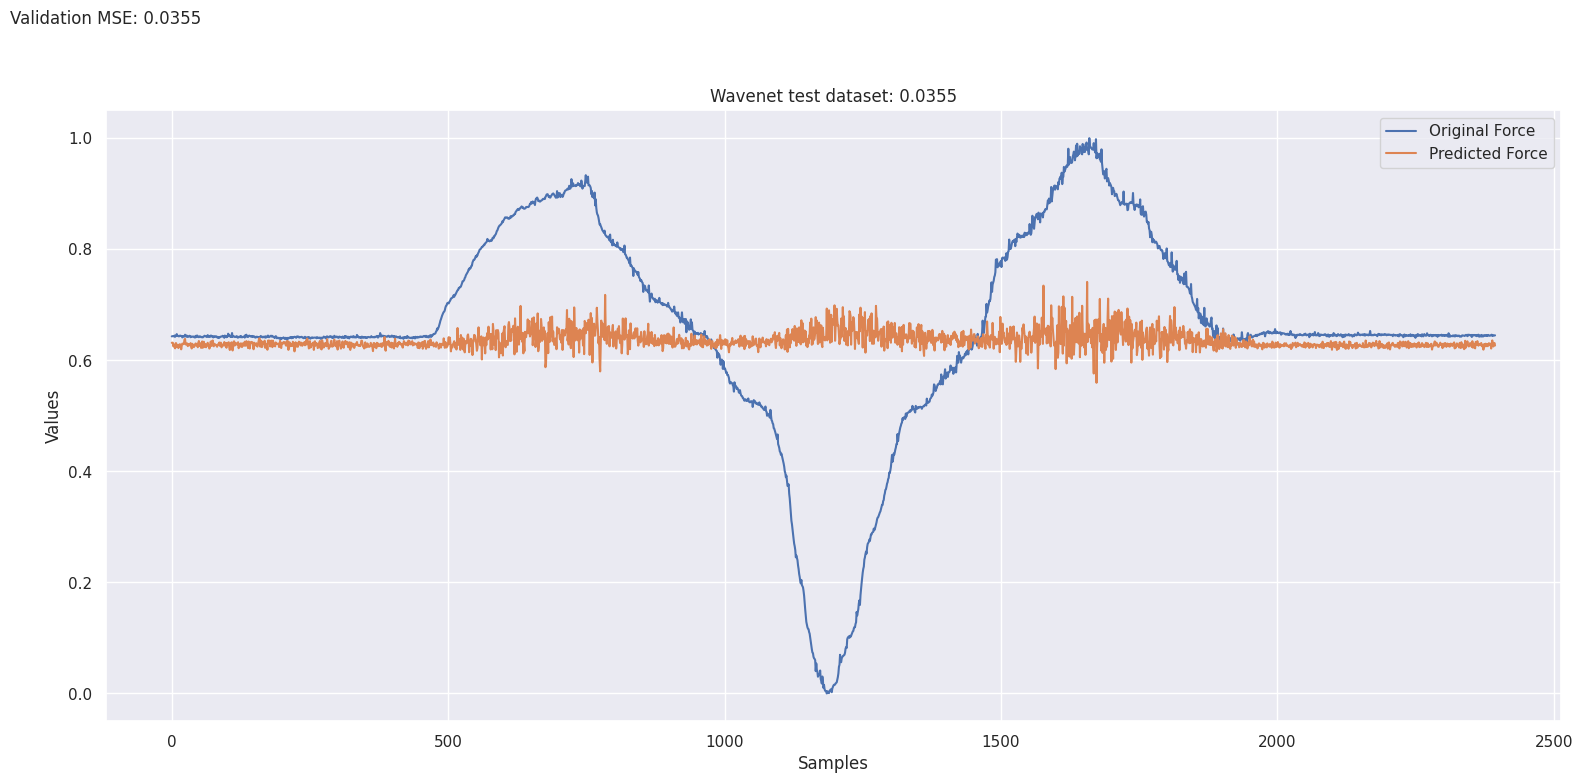

In [ ]:
predicted_test = np.array(predicted_test)
outputs = np.array(force_signal_test)
fig, ax = plt.subplots(figsize=(16, 8)) # nrows=5, ncols=1,
mse_ = calc_mse(predicted_test, outputs)
title = f"Wavenet test dataset: {mse_:.4f}"
for i in range(1):
    mse = calc_mse(predicted_test, outputs)
    ax.plot(outputs, label='Original Force')
    ax.plot(predicted_test[:,i], label='Predicted Force')
    ax.text(0, 1.15, f"Validation MSE: {mse:.4f}", transform=ax.transAxes,
        ha='center', va='center', fontsize=12)
    ax.set_title(f"Finger {i+1}")
    ax.set_xlabel("Samples")
    ax.set_ylabel("Values")
plt.title(title)
plt.tight_layout()
plt.legend()
plt.show()

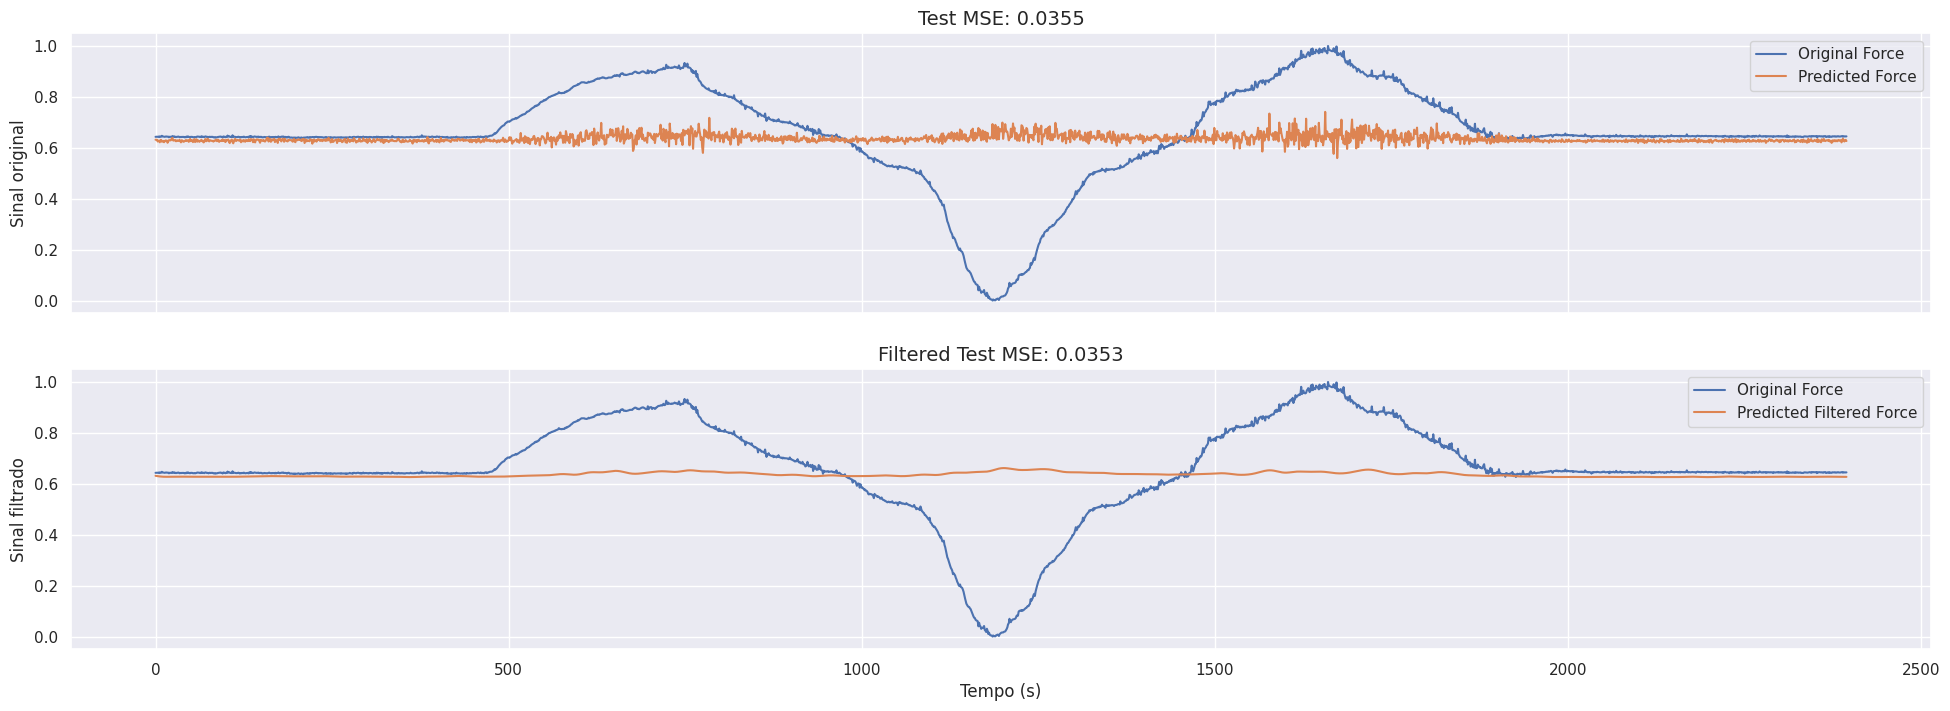

In [ ]:
from scipy.signal import butter, filtfilt, iirnotch

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

# Sample rate and desired cutoff frequency (in Hz)
fs = 2048.0
cutoff = 50.0

y = butter_lowpass_filter(predicted_test, cutoff, fs, order=4)

# Plotando os sinais
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(24, 8))
mse = calc_mse(predicted_test, outputs)
ax[0].set_title(f"Test MSE: {mse:.4f}", fontsize=14)
ax[0].plot(outputs, label='Original Force')
ax[0].plot(predicted_test, label='Predicted Force')
ax[0].set_ylabel('Sinal original')
ax[0].legend()

mse = calc_mse(y, outputs)
ax[1].set_title(f"Filtered Test MSE: {mse:.4f}", fontsize=14)
ax[1].plot(outputs, label='Original Force')
ax[1].plot(y, label='Predicted Filtered Force')
ax[1].set_ylabel('Sinal filtrado')
ax[1].set_xlabel('Tempo (s)')
ax[1].legend()
plt.show()

In [ ]:
print(f'r^2: {r2(y, outputs)}')

r^2: -464.8155541565516
